# Run Decipher on human hematopoiesis dataset (Velten 2017 scRNA)

**Project:** decipherATAC

**Author:** Azizi Lab - Sharanya Chatterjee

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scanpy as sc
import decipher as dc


/home/sc5625/.local/share/mamba/envs/decipher-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
adata = sc.read_h5ad("../datasets/hema/velten_rna.h5ad")

## Make sure adata.X contains raw counts for Decipher

In [3]:
import numpy as np

X = adata.X

print("min:", X.min())
print("max:", X.max())

# check if values are integers
is_integer_like = np.allclose(X.data, np.round(X.data))
print("integer-like:", is_integer_like)

min: 0.0
max: 78783.0
integer-like: True


In [4]:
adata

AnnData object with n_obs × n_vars = 1035 × 12553
    obs: 'plate', 'well', 'facs_fsc.area', 'facs_fsc_height', 'facs_ssc.area', 'facs_ssc_height', 'facs_cd45ra', 'facs_cd135', 'facs_cd90', 'facs_cd49f', 'facs_lin', 'facs_cd34', 'facs_cd38', 'facs_cd10', 'culture_key', 'culture_cells_in_colony', 'culture_mk_cd41+', 'culture_ery_cd235+', 'culture_total_number_of_my_cd33+', 'facs_pseudotime', 'fate_stemness', 'n_genes', 'dpt_pseudotime'
    var: 'n_cells'
    obsm: 'X_diffmap', 'X_pca', 'X_umap'
    layers: 'counts'

## Run Decipher

2026-04-25 02:35:20,478 | INFO : Early stopping has been triggered..09) | val ll: 28065.91:  10%| | 105/1000 [0
2026-04-25 02:35:20,608 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-04-25 02:35:20,609 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-04-25 02:35:20,613 | INFO : Saving decipher model with run_id 2026-04-25-02-35-20-buoyant-rosy-tostada.


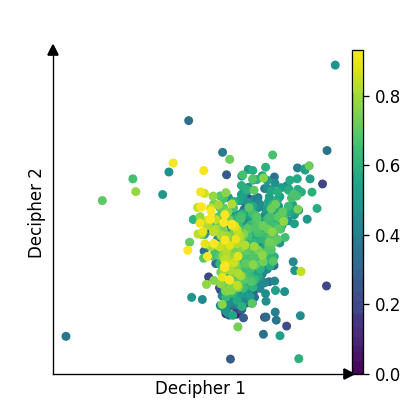

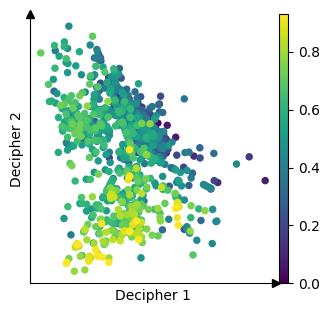

In [5]:
import matplotlib

decipher_config = dc.tl.DecipherConfig() # optional Decipher config

d1, val1 = dc.tl.decipher_train(
    adata, decipher_config, plot_kwargs={"color": "facs_pseudotime"}, plot_every_k_epochs=5,
)

In [9]:
%matplotlib inline

2026-04-25 02:40:30,953 | INFO : Clustering cells using scanpy Leiden algorithm.
2026-04-25 02:40:30,955 | INFO : Step 1: Computing neighbors with `sc.pp.neighbors`, with the representation decipher_z.
2026-04-25 02:40:30,971 | INFO : Step 2: Computing clusters with `sc.tl.leiden`, and resolution 1.0.
2026-04-25 02:40:31,202 | INFO : Added `.obs['decipher_clusters']`: the cluster labels.


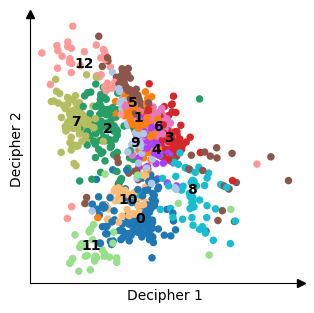

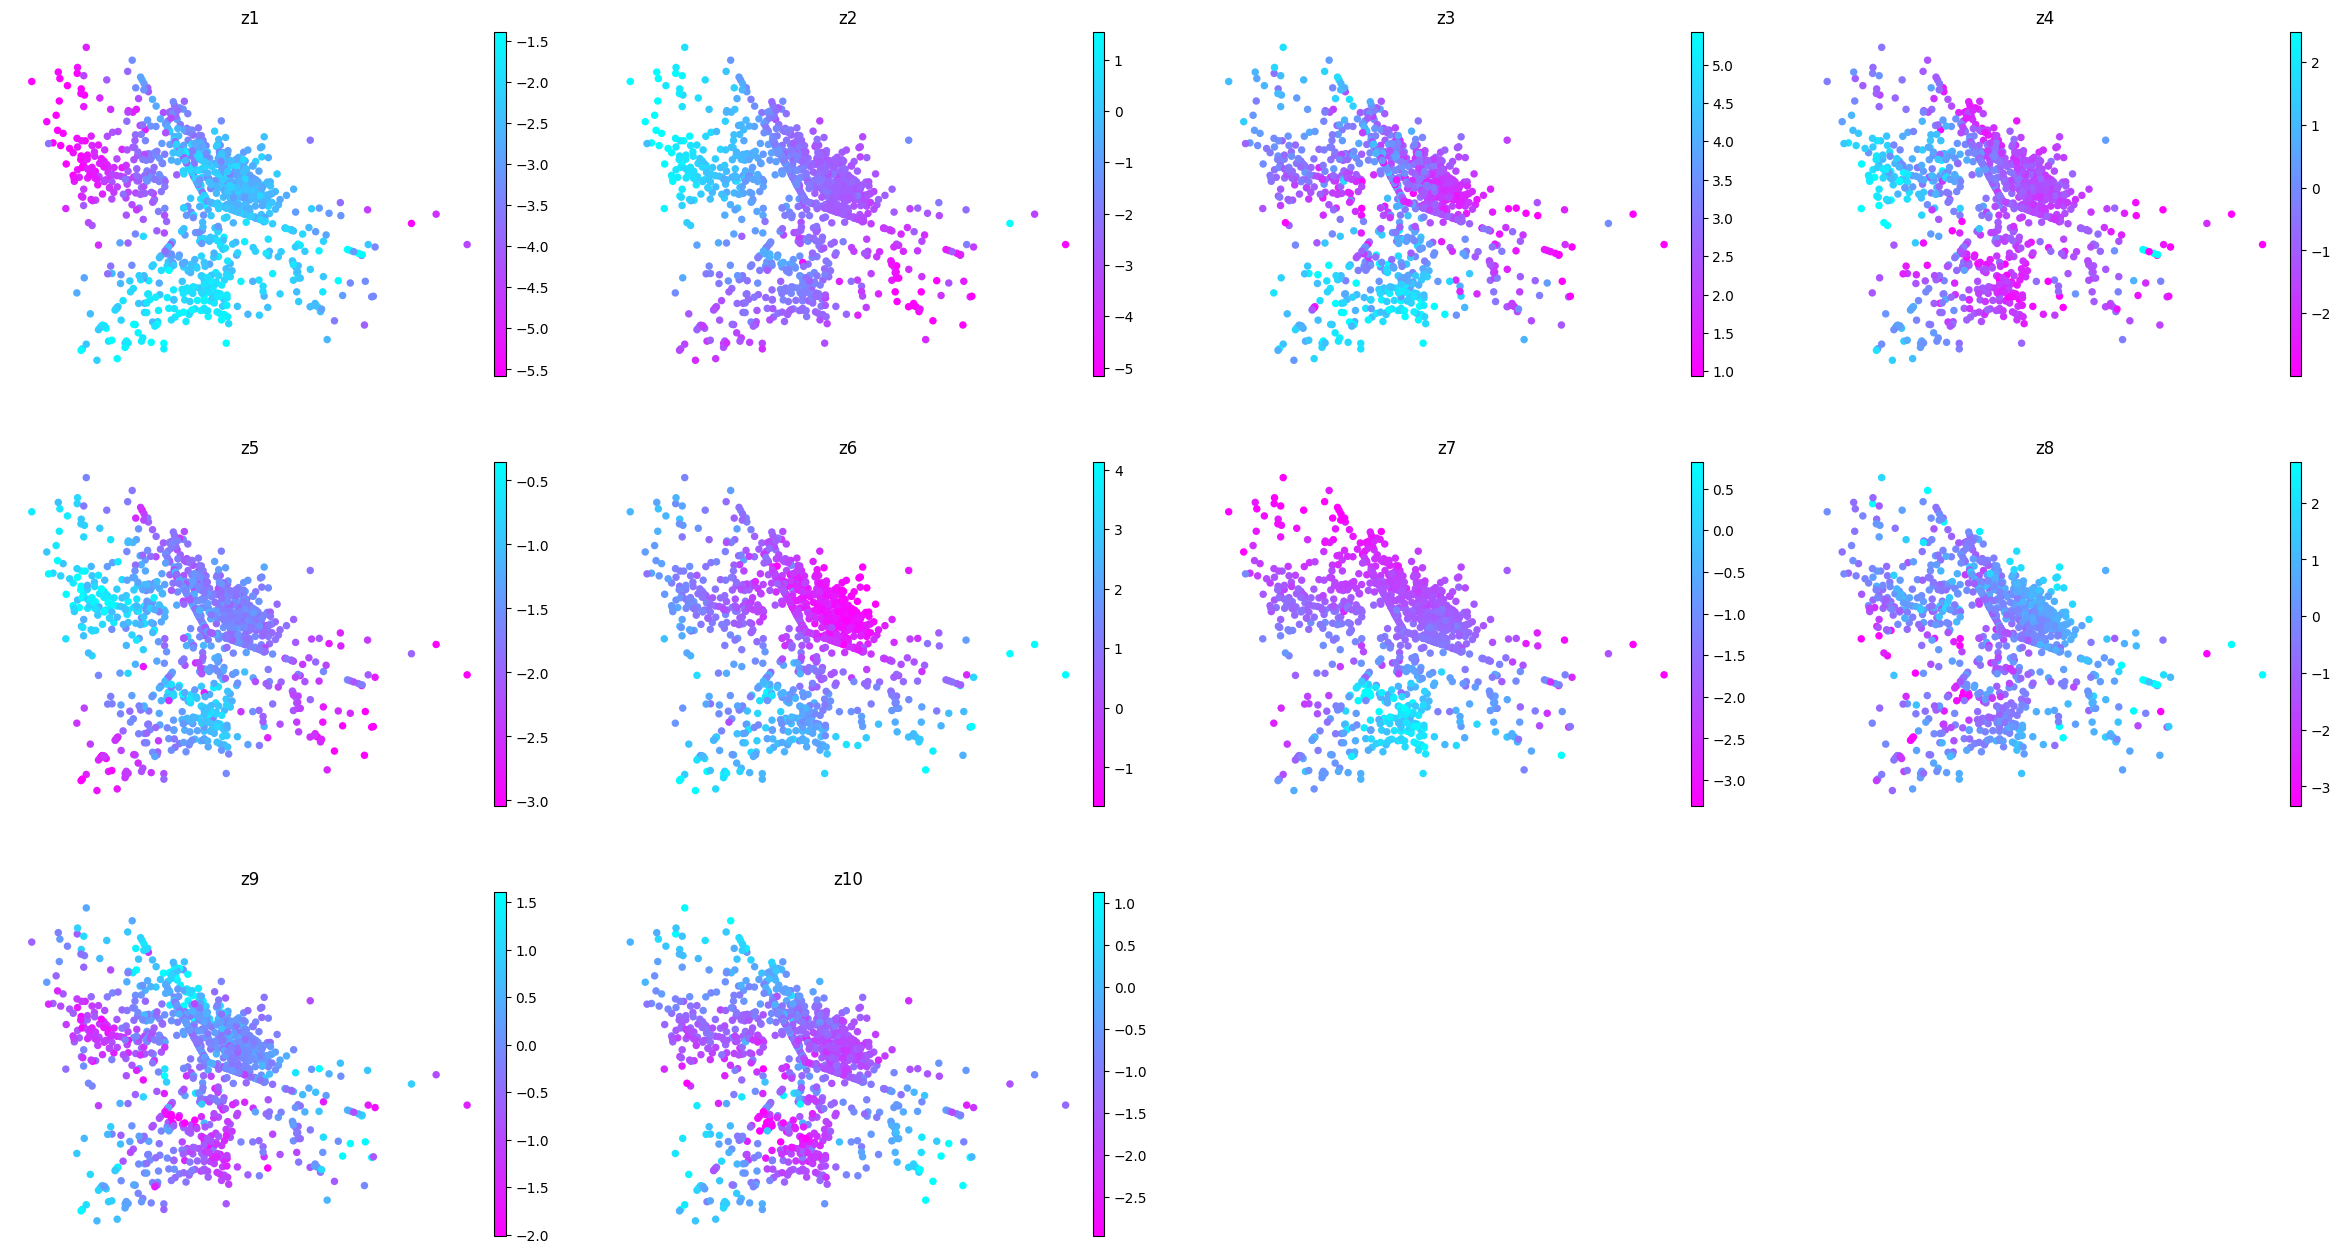

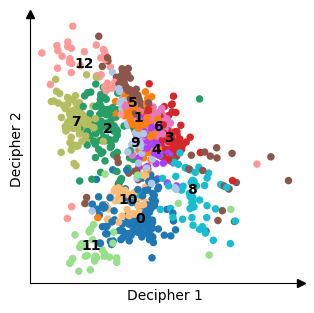

In [10]:
adata.uns.pop("diffmap_evals", None)
adata.obsm.pop("X_diffmap", None)

dc.tl.cell_clusters(adata)
dc.pl.decipher(adata, ["decipher_clusters"], legend_loc="on data");

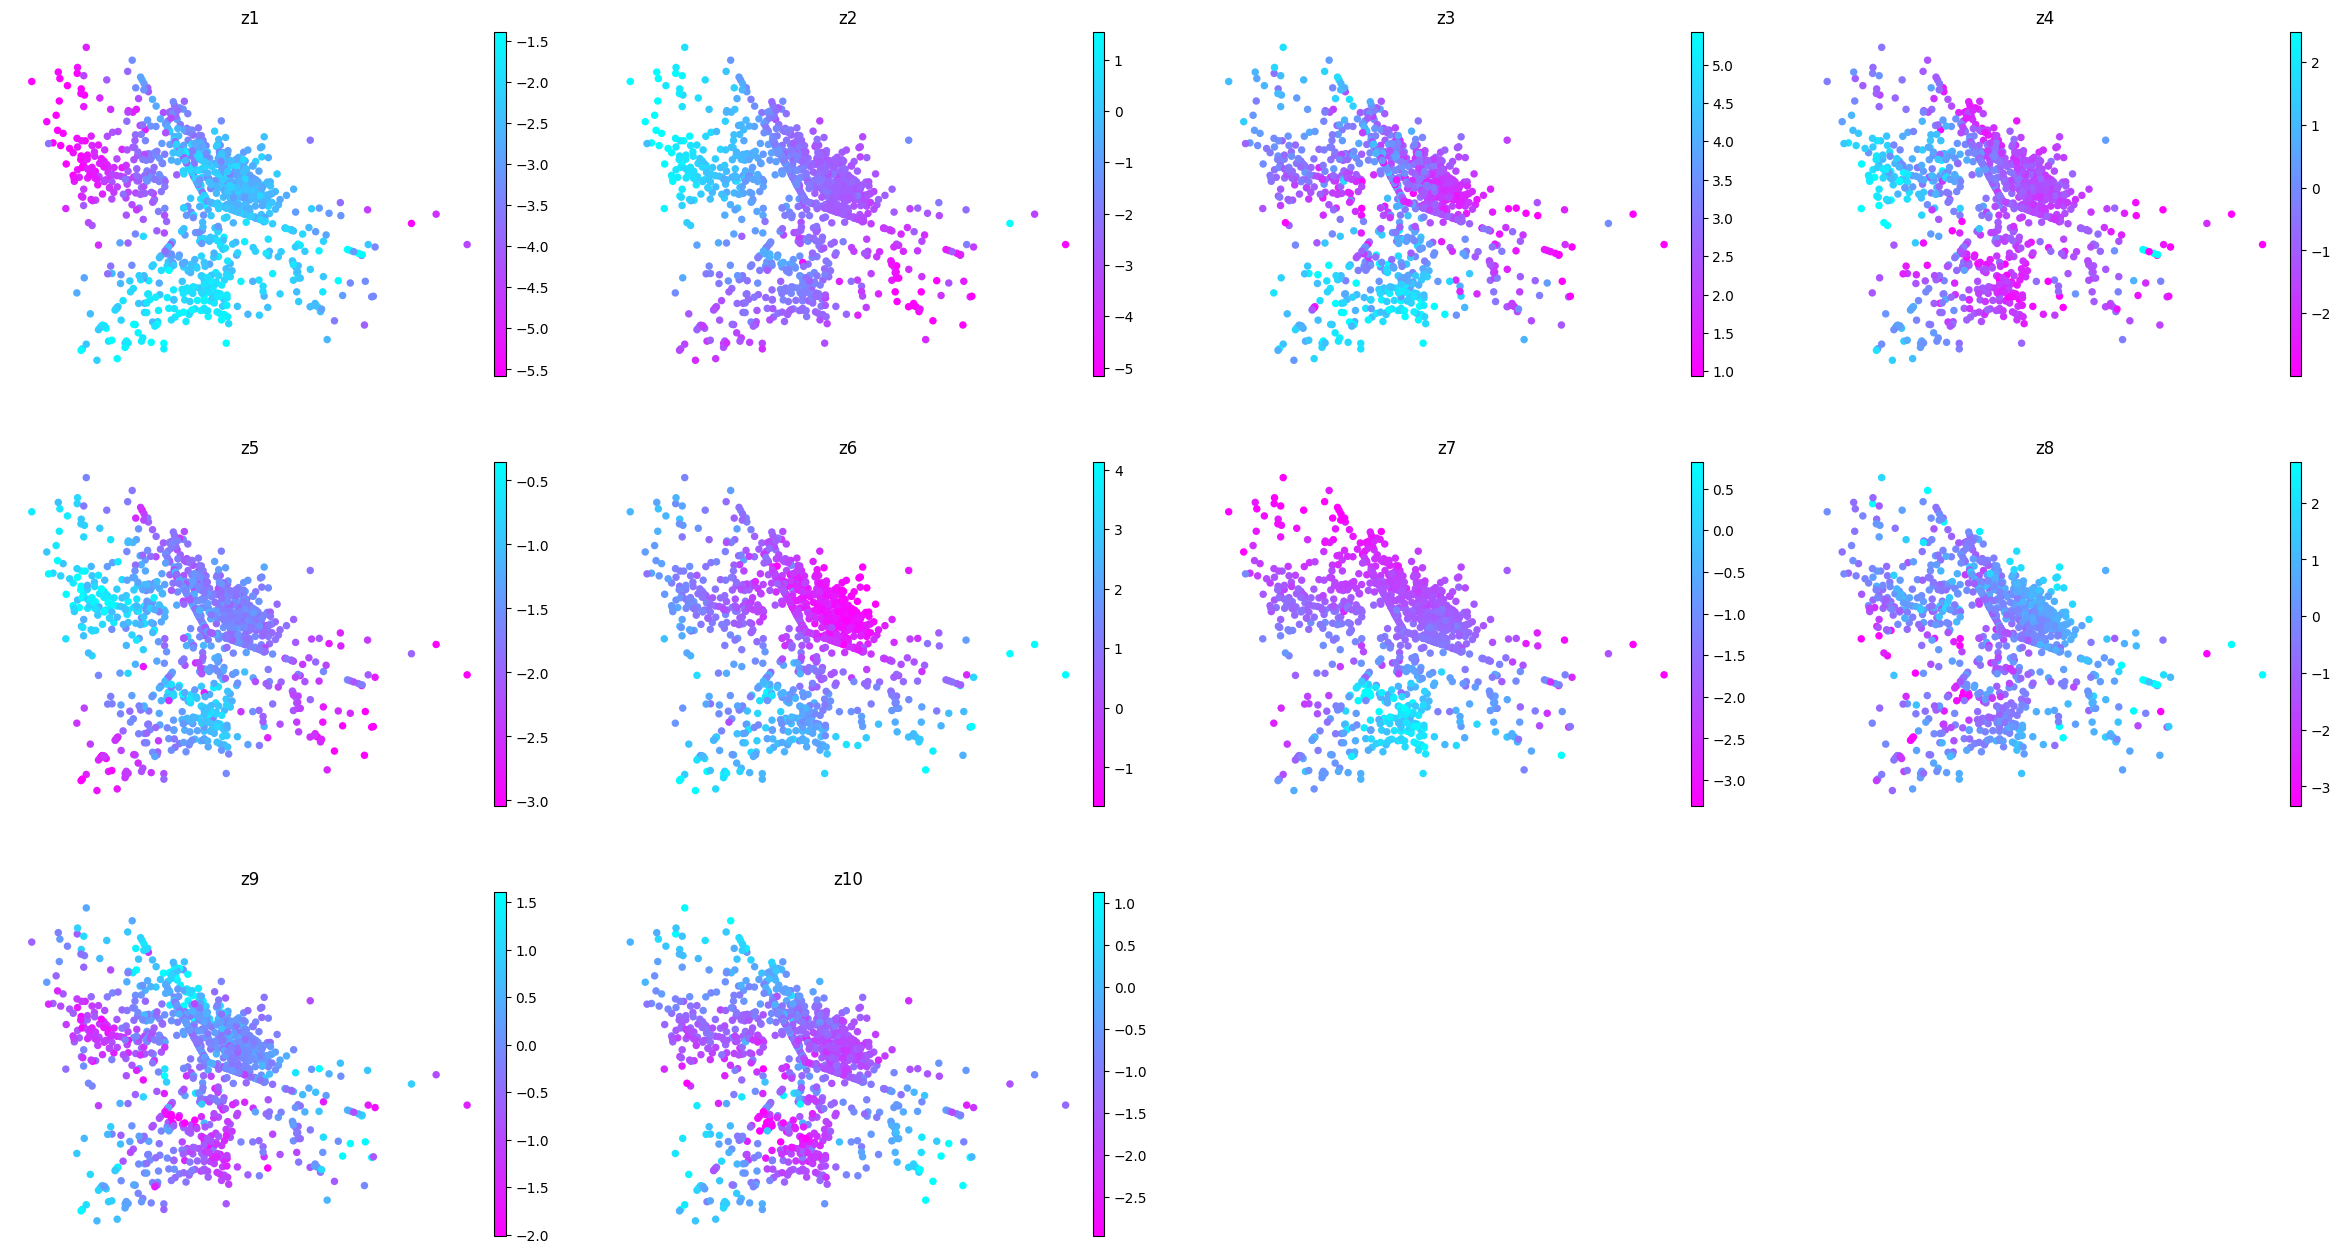

In [11]:
dc.pl.decipher_z(adata);

## Save outputs

In [12]:
adata.write("decipher_outputs/decipher_run_full.h5ad")

np.savez(
    "decipher_outputs/decipher_embeddings.npz",
    v=adata.obsm["decipher_v"],
    z=adata.obsm["decipher_z"]
)